# Compute Sentence Similarities

| Item | Description |
|---|---|
| Goal | Give every Item 1 sentence its cosine similarity to the two topic vectors, the definition (T3.5.1) and the centroid (T3.5.3), describe the two distributions, and fix the similarity threshold that the 1A scores use. |
| Input | `<scratch>/T3.6 - Firm Sentences/Processed/sentence_embeddings.npy` and `sentences.parquet` (T3.6.1, T3.6.4); `output/T3.5.1/topic_definition_embedding.npy`; `output/T3.5.3/topic_centroid_embedding.npy` and `statement_embeddings.npy`. |
| Output | `<scratch>/T3.6 - Firm Sentences/Processed/sentence_similarities.parquet` (`row`, `sim_definition`, `sim_centroid`, one row per sentence in table order); in `output/T3.6.5/`: `similarity_quantiles.csv`, `share_above_cutoffs.csv`, `statement_similarities.csv`, `similarity_threshold.csv` (the fixed threshold with the count of sentences at or above it, per vector), and one histogram per vector in PNG, SVG, and PDF. |
| Unit | A sentence. |
| Variables | • `sim_definition`: $\cos(e_k, c_{\text{def}}) = e_k \cdot c_{\text{def}}$ for sentence $k$, since both are unit vectors.<br>• `sim_centroid`: $e_k \cdot c_{\text{cent}}$. |
| Yardstick | The 374 legislator statements are the only texts known to be on topic; their similarities to the same two vectors are reported for comparison, with the caveat that they are hearing speech, not 10-K prose. |
| Threshold | One per vector, chosen by the author after reviewing the example sentences by band (Step 10) and the share tables: 0.67 for the definition vector and 0.75 for the centroid. They are named constants here and saved to `similarity_threshold.csv`; later notebooks read the saved values, never retype them. |

See `Topic Relevance Rebuild Plan.md` in the TEMP folder for the surrounding steps.


## Step 1. Import packages


In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display


## Step 2. Define file locations and settings

The similarity table goes to scratch beside the matrix; tables and figures go beside the notebook outputs. The candidate cutoffs are the bands T3.6.6 samples from.


In [2]:
PROJECT_FOLDER = Path("/project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis")
SCRATCH_FOLDER = Path("/scratch1/acroh/projects/LLM-Text-Analysis-and-Synthesis/T3-TEMP")
NOTEBOOK_SUBFOLDER = Path("T3 - Topic Relevance and Corporate Disclosure/TEMP")
NOTEBOOK_NAME = "T3.6.5"  # the identifier names this notebook's output folder
PROCESSED_FOLDER = SCRATCH_FOLDER / "T3.6 - Firm Sentences" / "Processed"
MATRIX_FILE = PROCESSED_FOLDER / "sentence_embeddings.npy"
SENTENCES_FILE = PROCESSED_FOLDER / "sentences.parquet"
SIMILARITIES_FILE = PROCESSED_FOLDER / "sentence_similarities.parquet"
DEFINITION_FILE = PROJECT_FOLDER / NOTEBOOK_SUBFOLDER / "output/T3.5.1/topic_definition_embedding.npy"
CENTROID_FILE = PROJECT_FOLDER / NOTEBOOK_SUBFOLDER / "output/T3.5.3/topic_centroid_embedding.npy"
STATEMENT_EMBEDDINGS_FILE = PROJECT_FOLDER / NOTEBOOK_SUBFOLDER / "output/T3.5.3/statement_embeddings.npy"
OUTPUT_FOLDER = PROJECT_FOLDER / NOTEBOOK_SUBFOLDER / "output" / NOTEBOOK_NAME

YEAR_MIN = 1999
YEAR_MAX = 2025
CHUNK_ROWS = 200_000  # rows of the matrix read per pass
QUANTILES = [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
CANDIDATE_CUTOFFS = [round(value, 2) for value in np.arange(0.50, 0.851, 0.05)]  # the bands sampled in T3.6.6
EXAMPLES_PER_BAND = 3
RANDOM_SEED = 0
BIN_WIDTH = 0.01
SIMILARITY_THRESHOLDS = {"definition": 0.67, "centroid": 0.75}  # one per vector; chosen by the author after reviewing the example sentences by band
THRESHOLD_REASON = "Reviewed the example sentences by similarity band and the share tables; chose 0.67 for the definition vector and 0.75 for the centroid."
DECIDED_BY = "author, by hand"
OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)
print(f"Similarities: {SIMILARITIES_FILE}")
print(f"Outputs: {OUTPUT_FOLDER}")


Similarities: /scratch1/acroh/projects/LLM-Text-Analysis-and-Synthesis/T3-TEMP/T3.6 - Firm Sentences/Processed/sentence_similarities.parquet
Outputs: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T3 - Topic Relevance and Corporate Disclosure/TEMP/output/T3.6.5


## Step 3. Apply the figure style

The shared canvas, font, colors, and margins; one series per figure, so BLUE throughout.


In [3]:
RED = "#B31942"
BLUE = "#0A3161"
MIDNIGHT_BLUE = "#004953"
GREY = "#A6A6A8"
BLACK = "#101820"
FIGURE_WIDTH = 9
FIGURE_HEIGHT = 6
MARGIN_INCHES = 0.5 / 2.54
EXPORT_DPI = 300

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif"]
plt.rcParams["font.size"] = 11
plt.rcParams["figure.figsize"] = (FIGURE_WIDTH, FIGURE_HEIGHT)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["axes.unicode_minus"] = True
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.grid.axis"] = "y"
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["grid.color"] = GREY
plt.rcParams["grid.linewidth"] = 0.5
plt.rcParams["text.color"] = BLACK
plt.rcParams["axes.labelcolor"] = BLACK
plt.rcParams["axes.edgecolor"] = BLACK
plt.rcParams["xtick.color"] = BLACK
plt.rcParams["ytick.color"] = BLACK


## Step 4. Load the topic vectors

Both must have unit length so the dot product is the cosine.


In [4]:
definition_vector = np.load(DEFINITION_FILE)[0].astype(np.float32)
centroid_vector = np.load(CENTROID_FILE)[0].astype(np.float32)
assert abs(np.linalg.norm(definition_vector) - 1) < 1e-4 and abs(np.linalg.norm(centroid_vector) - 1) < 1e-4
print(f"Definition vector {definition_vector.shape}; centroid vector {centroid_vector.shape}; cosine between them {definition_vector @ centroid_vector:.3f}")


Definition vector (1024,); centroid vector (1024,); cosine between them 0.745


## Step 5. Load the sentence table and open the matrix

The matrix is memory-mapped; it must have one row per sentence.


In [5]:
sentences = pd.read_parquet(SENTENCES_FILE)
matrix = np.load(MATRIX_FILE, mmap_mode="r")
assert matrix.shape[0] == len(sentences) and matrix.dtype == np.float16
n_filings = sentences["accessionNo"].nunique()
print(f"Sentences: {len(sentences):,} from {n_filings:,} filings; matrix {matrix.shape}, {matrix.dtype}")


Sentences: 5,647,505 from 18,779 filings; matrix (5647505, 1024), float16


## Step 6. Compute the two similarities in chunks

Each chunk of rows is converted to float32 and multiplied by each topic vector. The result is one similarity per sentence per vector.


In [6]:
started = time.time()
similarities = pd.DataFrame({"row": np.arange(len(sentences), dtype=np.int64)})
sim_definition = np.empty(len(sentences), dtype=np.float32)
sim_centroid = np.empty(len(sentences), dtype=np.float32)
for start in range(0, len(sentences), CHUNK_ROWS):
    block = np.asarray(matrix[start:start + CHUNK_ROWS], dtype=np.float32)
    sim_definition[start:start + CHUNK_ROWS] = block @ definition_vector
    sim_centroid[start:start + CHUNK_ROWS] = block @ centroid_vector
similarities["sim_definition"] = sim_definition
similarities["sim_centroid"] = sim_centroid
assert similarities[["sim_definition", "sim_centroid"]].abs().le(1.0001).all().all()
print(f"Computed {len(similarities):,} × 2 similarities in {(time.time() - started) / 60:.1f} minutes")
display(similarities.head(3))


Computed 5,647,505 × 2 similarities in 0.6 minutes


,row,sim_definition,sim_centroid
0,0,0.366893,0.475178
1,1,0.416137,0.503914
2,2,0.434045,0.514493


## Step 7. Quantiles of the two distributions

Where the bulk and the upper tail sit for each vector.


In [7]:
quantile_table = pd.DataFrame({
    "definition": np.quantile(similarities["sim_definition"], QUANTILES),
    "centroid": np.quantile(similarities["sim_centroid"], QUANTILES),
}, index=[f"p{q * 100:g}" for q in QUANTILES]).T.round(3)
quantile_table.to_csv(OUTPUT_FOLDER / "similarity_quantiles.csv", index_label="vector")
display(quantile_table)


,p1,p5,p10,p25,p50,p75,p90,p95,p99,p99.9
definition,0.256,0.291,0.312,0.349,0.392,0.436,0.479,0.508,0.571,0.674
centroid,0.398,0.431,0.449,0.481,0.520,0.560,0.597,0.621,0.670,0.741


## Step 8. Share of sentences at or above candidate cutoffs

The same cutoff selects very different shares under the two vectors; this table is the first reason the thresholds are fixed per vector.


In [8]:
share_table = pd.DataFrame({
    "cutoff": CANDIDATE_CUTOFFS,
    "definition_share": [(similarities["sim_definition"] >= cutoff).mean() for cutoff in CANDIDATE_CUTOFFS],
    "definition_sentences": [int((similarities["sim_definition"] >= cutoff).sum()) for cutoff in CANDIDATE_CUTOFFS],
    "centroid_share": [(similarities["sim_centroid"] >= cutoff).mean() for cutoff in CANDIDATE_CUTOFFS],
    "centroid_sentences": [int((similarities["sim_centroid"] >= cutoff).sum()) for cutoff in CANDIDATE_CUTOFFS],
})
share_table.to_csv(OUTPUT_FOLDER / "share_above_cutoffs.csv", index=False)
display(share_table.style.format({"definition_share": "{:.3%}", "centroid_share": "{:.3%}", "definition_sentences": "{:,}", "centroid_sentences": "{:,}"}))


,cutoff,definition_share,definition_sentences,centroid_share,centroid_sentences
0,0.500000,6.040%,"341,099",63.508%,"3,586,621"
1,0.550000,1.737%,"98,114",30.600%,"1,728,120"
2,0.600000,0.477%,"26,960",9.251%,"522,426"
3,0.650000,0.160%,"9,060",1.958%,"110,606"
4,0.700000,0.057%,"3,212",0.370%,"20,901"
5,0.750000,0.011%,601,0.070%,"3,956"
6,0.800000,0.001%,37,0.003%,177
7,0.850000,0.000%,0,0.000%,13


## Step 9. The legislator statements as a yardstick

The 374 statements are on topic by construction. Their similarities to the two vectors show what on-topic text scores, with the caveat that they are speech rather than filing prose.


In [9]:
statement_embeddings = np.load(STATEMENT_EMBEDDINGS_FILE).astype(np.float32)
statement_table = pd.DataFrame({
    "definition": np.quantile(statement_embeddings @ definition_vector, QUANTILES),
    "centroid": np.quantile(statement_embeddings @ centroid_vector, QUANTILES),
}, index=[f"p{q * 100:g}" for q in QUANTILES]).T.round(3)
statement_table.to_csv(OUTPUT_FOLDER / "statement_similarities.csv", index_label="vector")
print(f"Statements: {len(statement_embeddings):,}")
display(statement_table)


Statements: 374


,p1,p5,p10,p25,p50,p75,p90,p95,p99,p99.9
definition,0.366,0.412,0.457,0.507,0.565,0.613,0.659,0.677,0.722,0.731
centroid,0.551,0.641,0.678,0.717,0.759,0.795,0.819,0.831,0.857,0.878


## Step 10. Example sentences by similarity band

Three random sentences per band and vector, so the reader can see what each level of similarity looks like before any threshold is fixed.


In [10]:
rng = np.random.default_rng(RANDOM_SEED)
band_edges = CANDIDATE_CUTOFFS + [1.01]
example_rows = []
for vector_name, column in [("definition", "sim_definition"), ("centroid", "sim_centroid")]:
    for low, high in zip(band_edges[:-1], band_edges[1:]):
        in_band = np.flatnonzero((similarities[column] >= low) & (similarities[column] < high))
        chosen = rng.choice(in_band, size=min(EXAMPLES_PER_BAND, len(in_band)), replace=False) if len(in_band) else []
        for row in chosen:
            example_rows.append({
                "vector": vector_name, "band": f"[{low:.2f}, {min(high, 1.0):.2f})", "n_in_band": len(in_band),
                "similarity": round(float(similarities[column].iloc[row]), 3), "sentence": sentences["sentence"].iloc[row],
            })
examples = pd.DataFrame(example_rows)
pd.set_option("display.max_colwidth", 180)
display(examples)


,vector,band,n_in_band,similarity,sentence
0,definition,"[0.50, 0.55)",242985,0.514,"Our Communications segment provides components, modules and subsystems used by communications equipment providers for telecommunications, and data communications."
1,definition,"[0.50, 0.55)",242985,0.500,• configure content to match products and services; and
2,definition,"[0.50, 0.55)",242985,0.503,Application of various other federal and state environmental laws could also result in the imposition of liability on us for costs associated with environmental hazards.
3,definition,"[0.55, 0.60)",71154,0.550,(a) Represents loans to individual and small business consumers.
4,definition,"[0.55, 0.60)",71154,0.559,"For information regarding competition affecting the Company’s Consumer Domestic and Consumer International Products businesses, see “Competitive Environment” in “Management’s D..."
5,definition,"[0.55, 0.60)",71154,0.596,We discuss Senate Bill 1 in detail in the Residential Customers section.
6,definition,"[0.60, 0.65)",17900,0.601,"We are subject to various federal, state, and local environmental laws, including with respect to the sale, transportation, storage, handling, and disposal of hazardous or pote..."
7,definition,"[0.60, 0.65)",17900,0.616,Federal Regulation of Sales Prices and Transportation
8,definition,"[0.60, 0.65)",17900,0.615,"In addition, to the extent we offer products and services to on-line consumers outside the U.S., the laws and regulations of foreign jurisdictions, including, without limitatio..."
9,definition,"[0.65, 0.70)",5848,0.671,"(c) laws outside the United States, including the European Union's General Data Protection Regulation, Canada’s Personal Information Protection and Electronic Documents Act and..."


## Step 11. Fix the threshold and count the sentences above it

The thresholds are a decision, one per vector, recorded here with the reason. For each vector, count the sentences at or above its threshold and the filings that have at least one such sentence.


In [11]:
threshold_rows = []
for vector_name, column in [("definition", "sim_definition"), ("centroid", "sim_centroid")]:
    threshold = SIMILARITY_THRESHOLDS[vector_name]
    above = similarities[column] >= threshold
    threshold_rows.append({
        "vector": vector_name,
        "threshold": threshold,
        "n_sentences_at_or_above": int(above.sum()),
        "share_at_or_above": float(above.mean()),
        "n_filings_with_any": int(sentences.loc[above.to_numpy(), "accessionNo"].nunique()),
        "n_firms_with_any": int(sentences.loc[above.to_numpy(), "gvkey"].nunique()),
        "decided_by": DECIDED_BY,
        "reason": THRESHOLD_REASON,
    })
threshold_table = pd.DataFrame(threshold_rows)
threshold_table.to_csv(OUTPUT_FOLDER / "similarity_threshold.csv", index=False)
for row in threshold_table.itertuples(index=False):
    print(f"{row.vector}: {row.n_sentences_at_or_above:,} sentences ({row.share_at_or_above:.3%}) at or above {row.threshold}, in {row.n_filings_with_any:,} filings and {row.n_firms_with_any:,} firms")
print(f"Saved: {OUTPUT_FOLDER / 'similarity_threshold.csv'}")
display(threshold_table.drop(columns="reason"))


definition: 6,183 sentences (0.109%) at or above 0.67, in 2,548 filings and 306 firms
centroid: 3,956 sentences (0.070%) at or above 0.75, in 2,031 filings and 265 firms
Saved: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T3 - Topic Relevance and Corporate Disclosure/TEMP/output/T3.6.5/similarity_threshold.csv


,vector,threshold,n_sentences_at_or_above,share_at_or_above,n_filings_with_any,n_firms_with_any,decided_by
0,definition,0.67,6183,0.001095,2548,306,"author, by hand"
1,centroid,0.75,3956,0.000700,2031,265,"author, by hand"


## Step 12. Save the similarity table

One row per sentence in table order, on scratch beside the matrix. T3.6.6 samples from it and the 1A score notebooks read it instead of recomputing.


In [12]:
similarities.to_parquet(SIMILARITIES_FILE, index=False)
print(f"Saved: {SIMILARITIES_FILE} ({SIMILARITIES_FILE.stat().st_size / 1e6:.0f} MB)")


Saved: /scratch1/acroh/projects/LLM-Text-Analysis-and-Synthesis/T3-TEMP/T3.6 - Firm Sentences/Processed/sentence_similarities.parquet (68 MB)


## Step 13. Draw the distribution against the definition vector

A histogram with a logarithmic count axis so the upper tail is visible, and a dashed vertical line at this vector's threshold.


**Figure 1. Cosine Similarity of Item 1 Sentences to the Topic Definition**

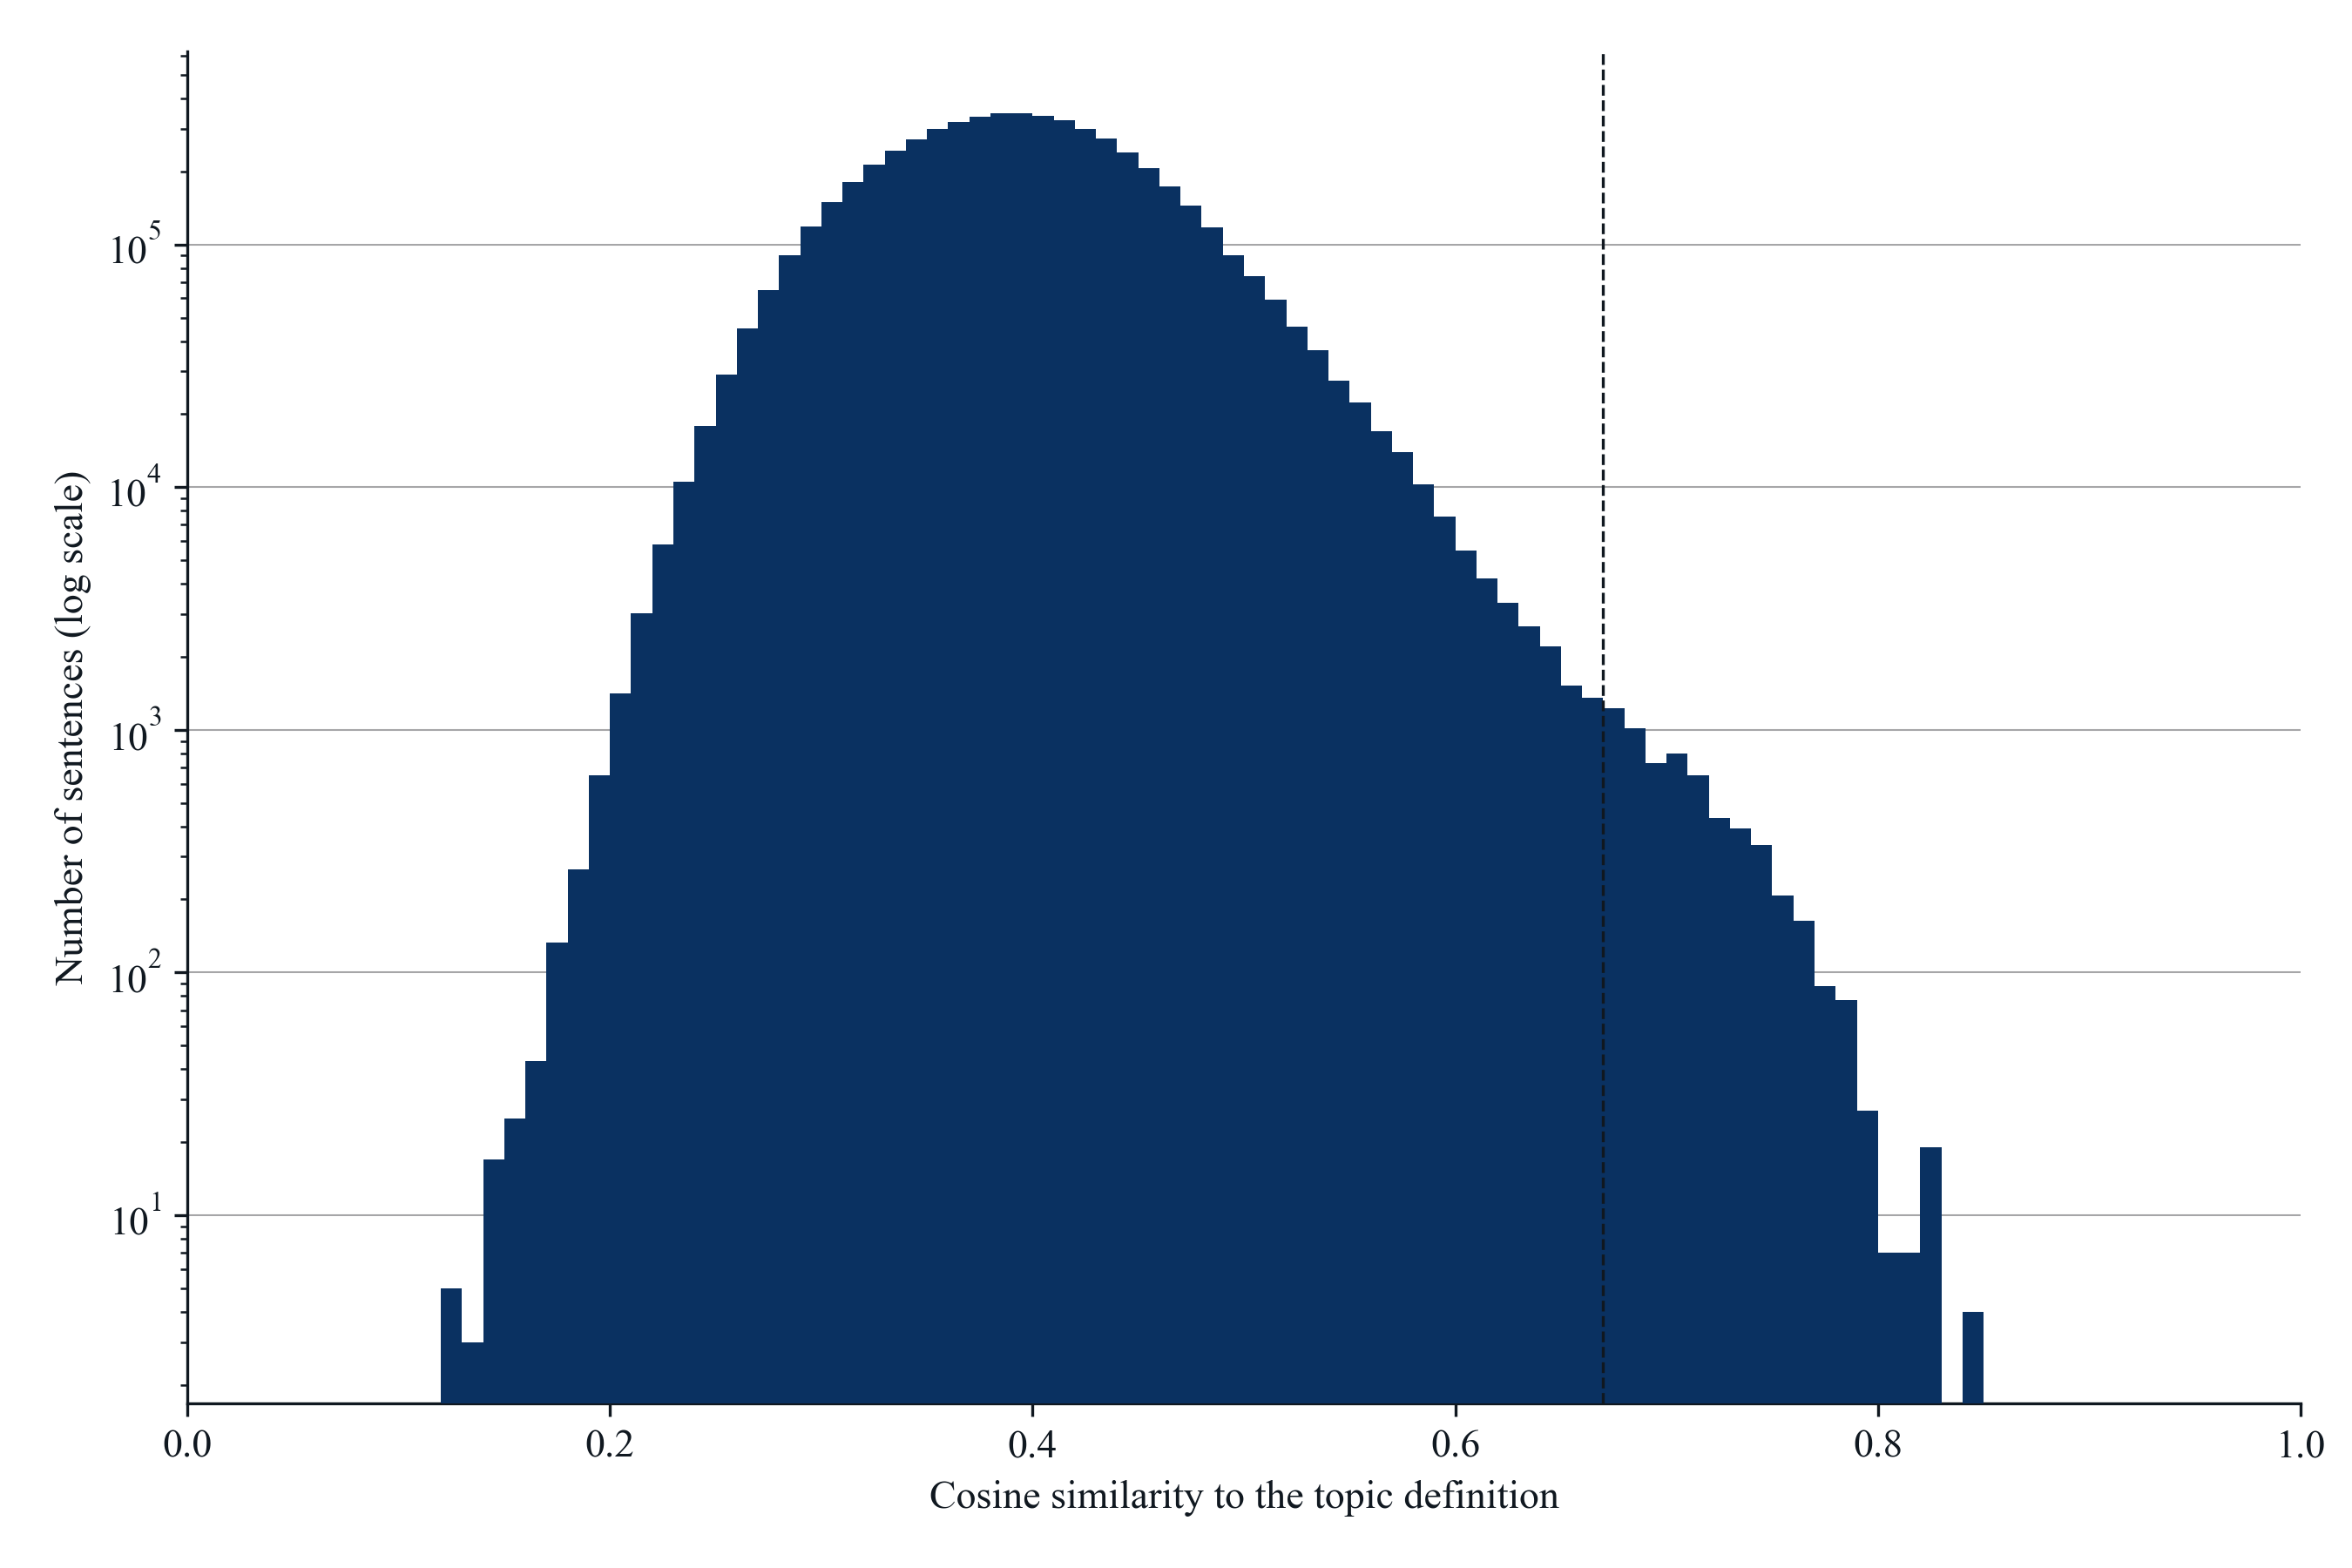

*Notes*: Sample: 5,647,505 Item 1 sentences from 18,779 S&P 500-ever 10-K filings, fiscal years 1999–2025. Cosine similarity is the dot product of unit-length bge-large-en-v1.5 embeddings (CLS pooling). Bins are 0.01 wide; the vertical axis is logarithmic so the upper tail is visible. The dashed vertical line marks this vector's threshold of 0.67: 6,183 sentences (0.109%) lie at or above it. The quantiles and the share of sentences above candidate cutoffs are in the tables saved beside this figure.

*Source*: Item 1 sections of 10-K filings from EDGAR; topic vectors from T3.5.1 and T3.5.3.

Saved PNG, SVG, and PDF: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T3 - Topic Relevance and Corporate Disclosure/TEMP/output/T3.6.5/fig_similarity_definition


In [13]:
figure_name = "fig_similarity_definition"
figure_title = "Figure 1. Cosine Similarity of Item 1 Sentences to the Topic Definition"
vector_name = "definition"
similarity_column = "sim_definition"
x_title = "Cosine similarity to the topic definition"
bin_edges = np.arange(0, 1 + BIN_WIDTH / 2, BIN_WIDTH)
threshold = SIMILARITY_THRESHOLDS[vector_name]
n_at_or_above = int((similarities[similarity_column] >= threshold).sum())
share_at_or_above = n_at_or_above / len(similarities)
figure, axis = plt.subplots()
figure.subplots_adjust(
    left=0.12, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.15
)
axis.hist(similarities[similarity_column], bins=bin_edges, color=BLUE, log=True, zorder=3)
axis.axvline(threshold, color=BLACK, linestyle="--", linewidth=0.8, zorder=4)
axis.set_xlim(0, 1)
axis.set_xlabel(x_title)
axis.set_ylabel("Number of sentences (log scale)")
axis.spines[["top", "right"]].set_visible(False)

figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
bottom_shift = (margin_pixels - axis.xaxis.label.get_window_extent(renderer).y0) / figure.bbox.height
figure.subplots_adjust(
    left=figure.subplotpars.left + left_shift,
    bottom=figure.subplotpars.bottom + bottom_shift,
)
for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)

figure_notes = (
    f"Sample: {len(similarities):,} Item 1 sentences from {n_filings:,} S&P 500-ever 10-K filings, fiscal years "
    f"{YEAR_MIN}–{YEAR_MAX}. Cosine similarity is the dot product of unit-length bge-large-en-v1.5 embeddings "
    f"(CLS pooling). Bins are {BIN_WIDTH} wide; the vertical axis is logarithmic so the upper tail is visible. "
    f"The dashed vertical line marks this vector's threshold of {threshold}: {n_at_or_above:,} sentences ({share_at_or_above:.3%}) lie at or above it. "
    "The quantiles and the share of sentences above candidate cutoffs are in the tables saved beside this figure."
)
display(Markdown(f"**{figure_title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {figure_notes}\n\n*Source*: Item 1 sections of 10-K filings from EDGAR; topic vectors from T3.5.1 and T3.5.3."))
print(f"Saved PNG, SVG, and PDF: {OUTPUT_FOLDER / figure_name}")


## Step 14. Draw the distribution against the centroid

Same drawing for the centroid vector.


**Figure 2. Cosine Similarity of Item 1 Sentences to the Statement Centroid**

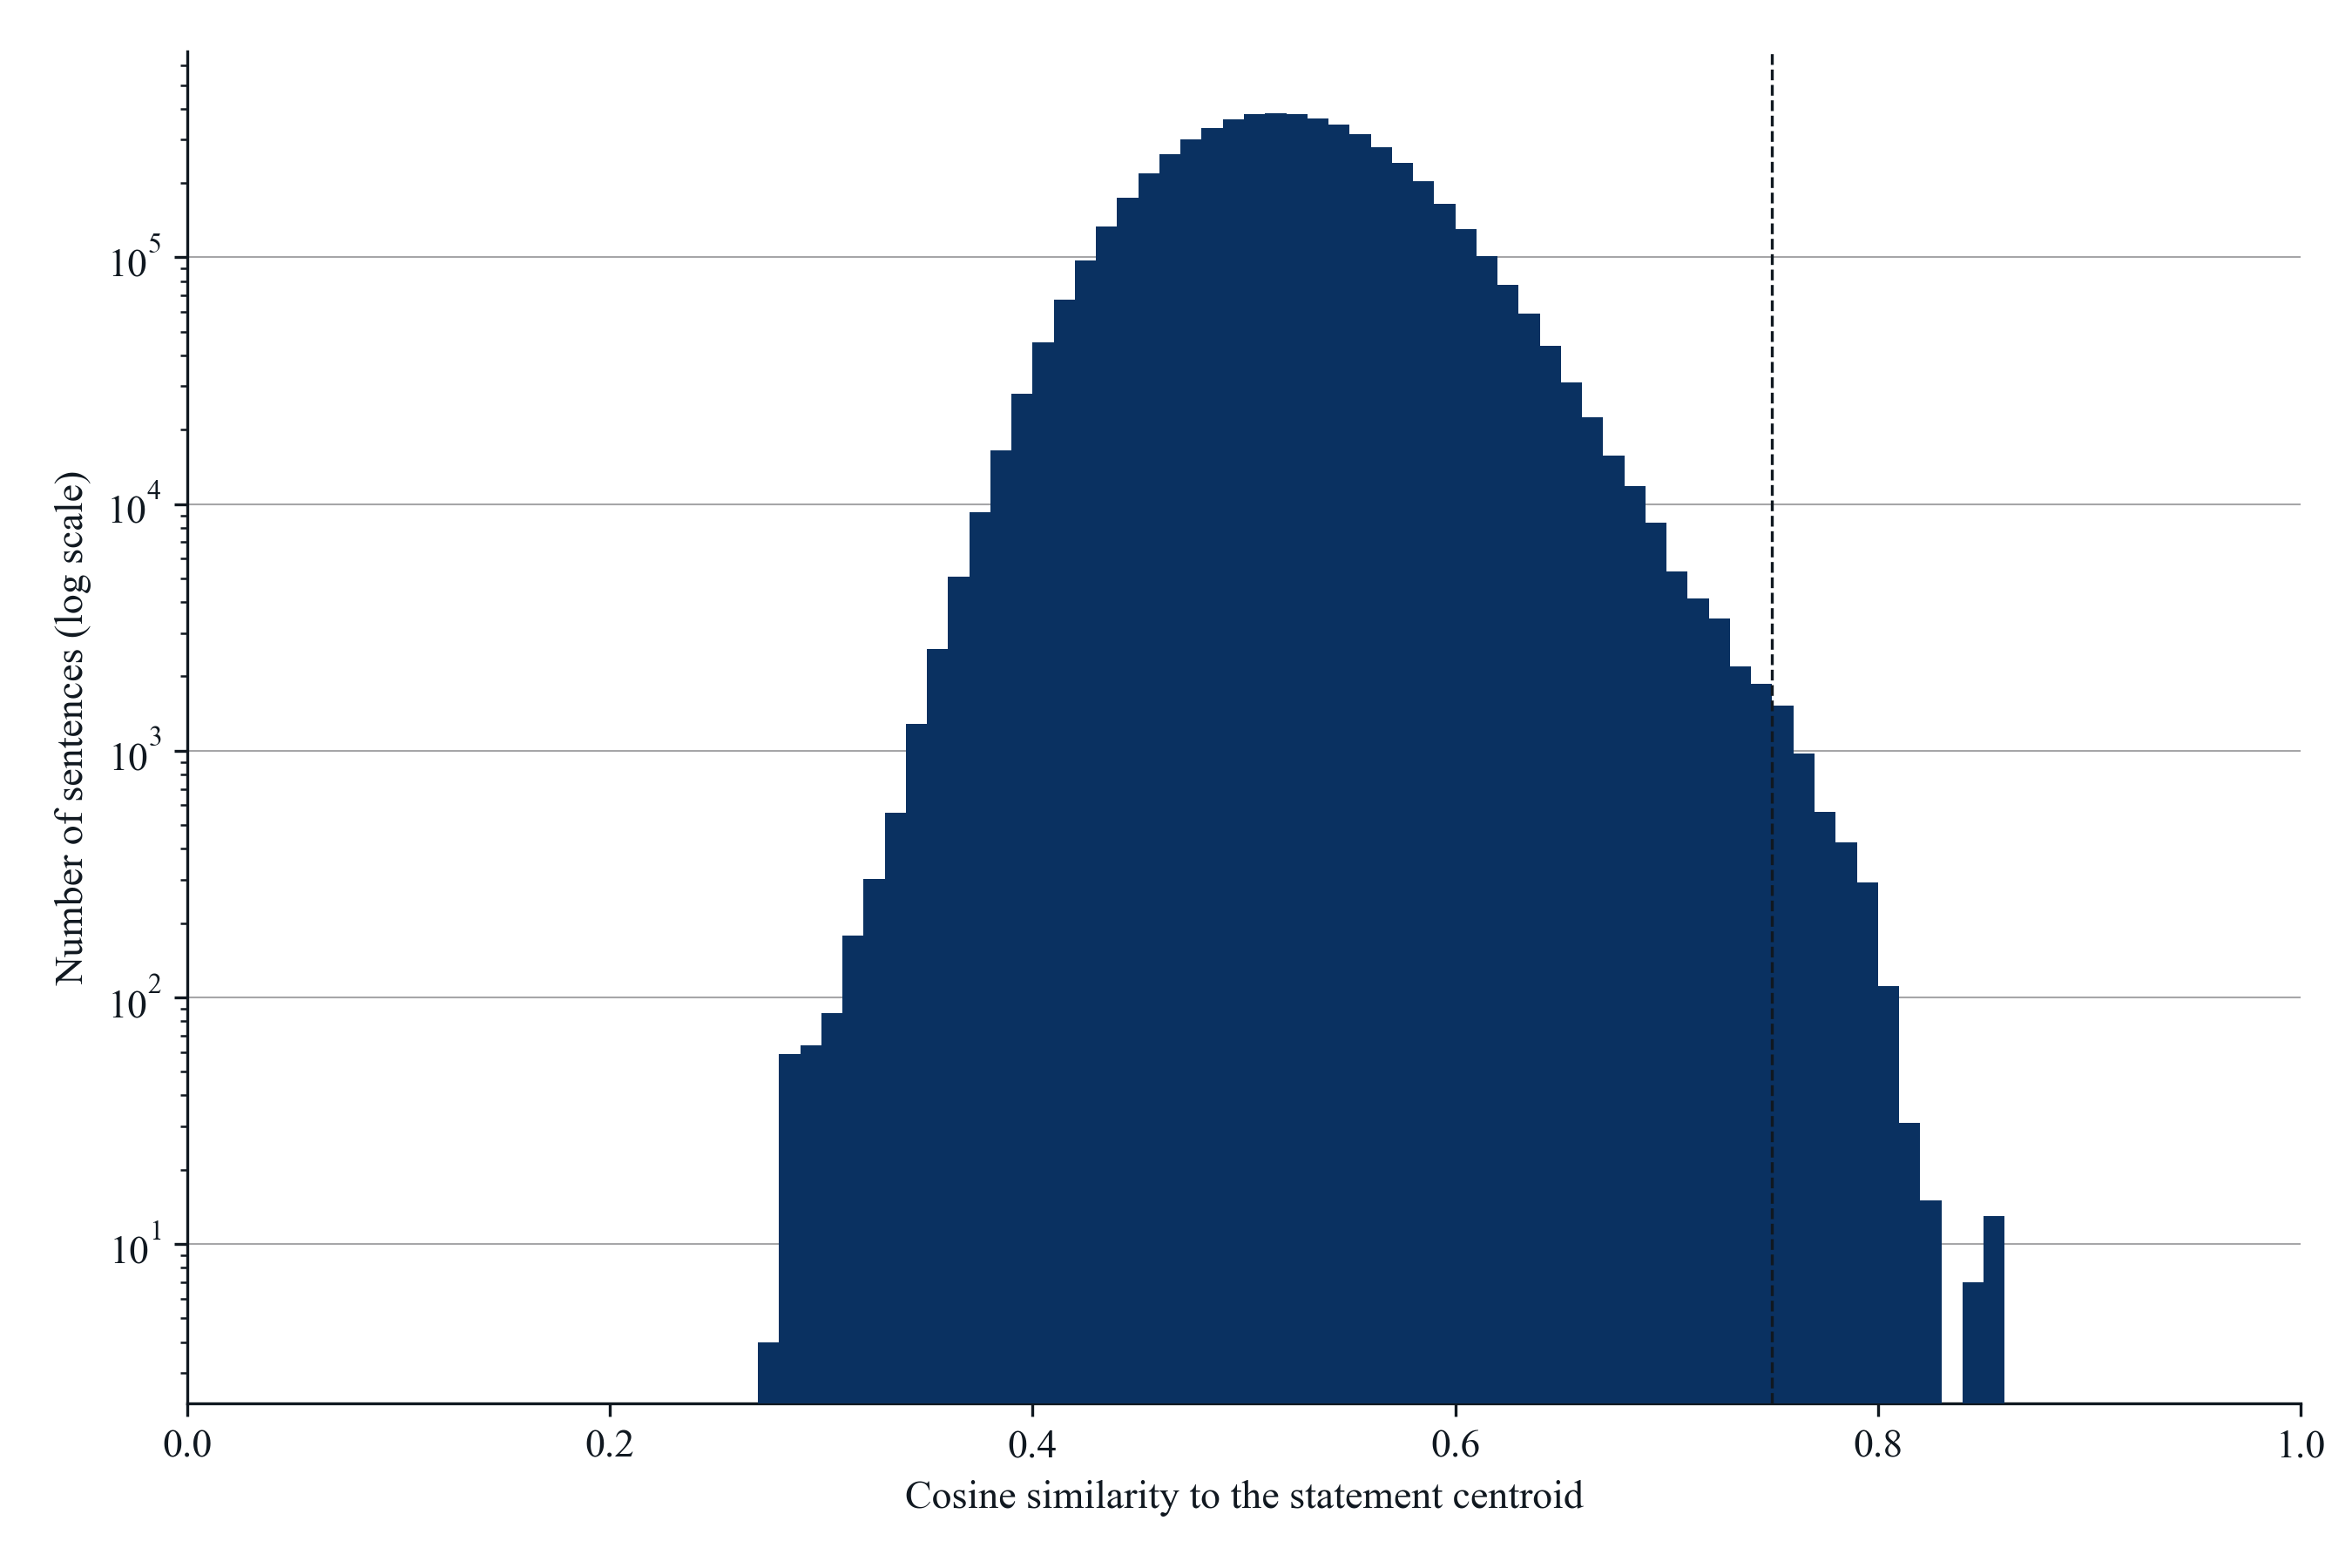

*Notes*: Sample: 5,647,505 Item 1 sentences from 18,779 S&P 500-ever 10-K filings, fiscal years 1999–2025. Cosine similarity is the dot product of unit-length bge-large-en-v1.5 embeddings (CLS pooling). Bins are 0.01 wide; the vertical axis is logarithmic so the upper tail is visible. The dashed vertical line marks this vector's threshold of 0.75: 3,956 sentences (0.070%) lie at or above it. The quantiles and the share of sentences above candidate cutoffs are in the tables saved beside this figure.

*Source*: Item 1 sections of 10-K filings from EDGAR; topic vectors from T3.5.1 and T3.5.3.

Saved PNG, SVG, and PDF: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T3 - Topic Relevance and Corporate Disclosure/TEMP/output/T3.6.5/fig_similarity_centroid


In [14]:
figure_name = "fig_similarity_centroid"
figure_title = "Figure 2. Cosine Similarity of Item 1 Sentences to the Statement Centroid"
vector_name = "centroid"
similarity_column = "sim_centroid"
x_title = "Cosine similarity to the statement centroid"
bin_edges = np.arange(0, 1 + BIN_WIDTH / 2, BIN_WIDTH)
threshold = SIMILARITY_THRESHOLDS[vector_name]
n_at_or_above = int((similarities[similarity_column] >= threshold).sum())
share_at_or_above = n_at_or_above / len(similarities)
figure, axis = plt.subplots()
figure.subplots_adjust(
    left=0.12, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.15
)
axis.hist(similarities[similarity_column], bins=bin_edges, color=BLUE, log=True, zorder=3)
axis.axvline(threshold, color=BLACK, linestyle="--", linewidth=0.8, zorder=4)
axis.set_xlim(0, 1)
axis.set_xlabel(x_title)
axis.set_ylabel("Number of sentences (log scale)")
axis.spines[["top", "right"]].set_visible(False)

figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
bottom_shift = (margin_pixels - axis.xaxis.label.get_window_extent(renderer).y0) / figure.bbox.height
figure.subplots_adjust(
    left=figure.subplotpars.left + left_shift,
    bottom=figure.subplotpars.bottom + bottom_shift,
)
for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)

figure_notes = (
    f"Sample: {len(similarities):,} Item 1 sentences from {n_filings:,} S&P 500-ever 10-K filings, fiscal years "
    f"{YEAR_MIN}–{YEAR_MAX}. Cosine similarity is the dot product of unit-length bge-large-en-v1.5 embeddings "
    f"(CLS pooling). Bins are {BIN_WIDTH} wide; the vertical axis is logarithmic so the upper tail is visible. "
    f"The dashed vertical line marks this vector's threshold of {threshold}: {n_at_or_above:,} sentences ({share_at_or_above:.3%}) lie at or above it. "
    "The quantiles and the share of sentences above candidate cutoffs are in the tables saved beside this figure."
)
display(Markdown(f"**{figure_title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {figure_notes}\n\n*Source*: Item 1 sections of 10-K filings from EDGAR; topic vectors from T3.5.1 and T3.5.3."))
print(f"Saved PNG, SVG, and PDF: {OUTPUT_FOLDER / figure_name}")
